## 1. Carregando e olhando os dados
A base tem 918 linhas e 12 colunas. Não tem `NaN` explícito, mas `Cholesterol` (172) e `RestingBP` (1) têm valores zerados que na prática são dados faltantes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# gambiarra pra funcionar tanto rodando da raiz quanto da pasta notebooks
try:
    df = pd.read_csv("database/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("notebooks/database/heart.csv")

print("shape:", df.shape)
display(df.head())

print("\nnulos:")
print(df.isnull().sum())

# n faz sentido colesterol ou pressao ser 0, entao conta como faltante tbm
print("\nzeros em Cholesterol:", (df["Cholesterol"] == 0).sum())
print("zeros em RestingBP:", (df["RestingBP"] == 0).sum())

shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



nulos:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

zeros em Cholesterol: 172
zeros em RestingBP: 1


## 2. Análise exploratória
Verificando o balanceamento das classes e a relação do tipo de dor no peito com a doença cardíaca.

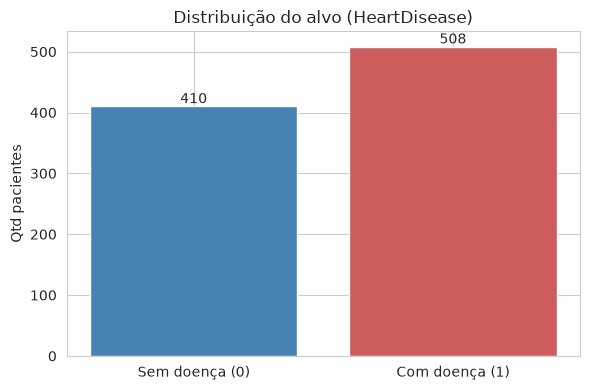

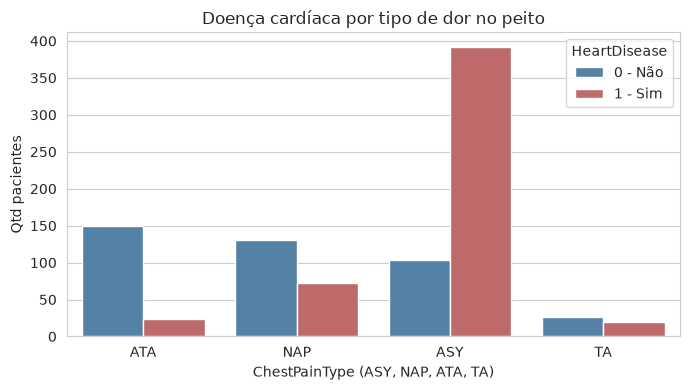

In [2]:
sns.set_style("whitegrid")

# grafico 1 - balanceamento das classes
plt.figure(figsize=(6, 4))
cont = df["HeartDisease"].value_counts().sort_index()
barras = plt.bar(["Sem doença (0)", "Com doença (1)"], cont.values, color=["steelblue", "indianred"])
plt.title("Distribuição do alvo (HeartDisease)")
plt.ylabel("Qtd pacientes")
plt.bar_label(barras)
plt.tight_layout()
plt.savefig("fig1_distribuicao_classes.png", dpi=300)
plt.show()

# grafico 2 - tipo de dor no peito vs doenca
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="ChestPainType", hue="HeartDisease", palette=["steelblue", "indianred"])
plt.title("Doença cardíaca por tipo de dor no peito")
plt.xlabel("ChestPainType (ASY, NAP, ATA, TA)")
plt.ylabel("Qtd pacientes")
plt.legend(["0 - Não", "1 - Sim"], title="HeartDisease")
plt.tight_layout()
plt.savefig("fig2_dor_peito_alvo.png", dpi=300)
plt.show()

## 3. Divisão dos dados (60 / 20 / 20)
Separando em treino, validação e teste mantendo a proporção das classes. O conjunto de teste fica guardado pra usar só no final.

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

# separa 20% pro teste e deixa 80% pra dividir entre treino e validacao
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 0.25 de 0.80 = 0.20 do total (fica 60 / 20 / 20)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print("treino:", X_train.shape, "-> prop positivos:", round(y_train.mean(), 3))
print("val:   ", X_val.shape, "-> prop positivos:", round(y_val.mean(), 3))
print("teste: ", X_test.shape, "-> prop positivos:", round(y_test.mean(), 3))

treino: (550, 11) -> prop positivos: 0.553
val:    (184, 11) -> prop positivos: 0.554
teste:  (184, 11) -> prop positivos: 0.554


## 4. Pré-processamento
Montando o pipeline com `ColumnTransformer` pra ajustar mediana, escala e one-hot encoding só no treino.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

col_zero = ["Cholesterol", "RestingBP"]
col_num = ["Age", "FastingBS", "MaxHR", "Oldpeak"]
col_cat = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

# trata 0 como valor faltante nessas duas colunas
prep_zero = Pipeline([
    ("imp", SimpleImputer(missing_values=0, strategy="median")),
    ("scaler", StandardScaler())
])

prep_num = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

prep_cat = Pipeline([
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

prep = ColumnTransformer([
    ("zero", prep_zero, col_zero),
    ("num", prep_num, col_num),
    ("cat", prep_cat, col_cat)
])

## 5. Modelo baseline (Random Forest)
Primeiro teste simples avaliando apenas na validação.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# junta o preprocessamento com o modelo pra n dar data leakage
clf = Pipeline([
    ("prep", prep),
    ("rf", RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

clf.fit(X_train, y_train)

pred = clf.predict(X_val)
prob = clf.predict_proba(X_val)[:, 1]

print("Acurácia: ", round(accuracy_score(y_val, pred), 4))
print("Precisão: ", round(precision_score(y_val, pred), 4))
print("Recall:   ", round(recall_score(y_val, pred), 4))
print("F1:       ", round(f1_score(y_val, pred), 4))
print("AUC-ROC:  ", round(roc_auc_score(y_val, prob), 4))
print("\nMatriz de confusão (validação):")
print(confusion_matrix(y_val, pred))

Acurácia:  0.8043
Precisão:  0.8173
Recall:    0.8333
F1:        0.8252
AUC-ROC:   0.9029

Matriz de confusão (validação):
[[63 19]
 [17 85]]
